## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

In [27]:
import pandas as pd

from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules

# to stop an annoying warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [28]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header=None,             # the file has no header row: line 1 is already a transaction
    names=["basket"],        # name the one column we create
    sep="|",                 # "|" never appears in this file, so each whole line lands in one column
    quoting=csv.QUOTE_NONE,  # treat any quote characters as ordinary text
)

In [29]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [30]:
long = (
    raw
    .assign(basket_id=raw.index)                    # use the row number as the basket ID
    .assign(item=raw["basket"].str.split(","))      # "milk,bread" becomes ["milk", "bread"]
    .explode("item")                                # one row per (basket, item)
    [["basket_id", "item"]]                         # keep only the two columns we need
    .reset_index(drop=True)                         # renumber the rows 0, 1, 2, ...
)

long["item"] = long["item"].str.strip()             # remove stray leading/trailing spaces

long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [31]:
basket = pd.crosstab(long["basket_id"], long["item"]).astype(bool)
basket

item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
basket_id,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
9831,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9832,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [32]:
basket_sizes = basket.sum(axis=1)
basket_sizes

,0
basket_id,
0,4
1,3
2,1
3,4
4,4
...,...
9830,17
9831,1
9832,10


3. Summarize the distribution of the number of items.

In [33]:
basket_sizes.describe()

,0
count,9835.000000
mean,4.409456
std,3.589385
min,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,32.000000


4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

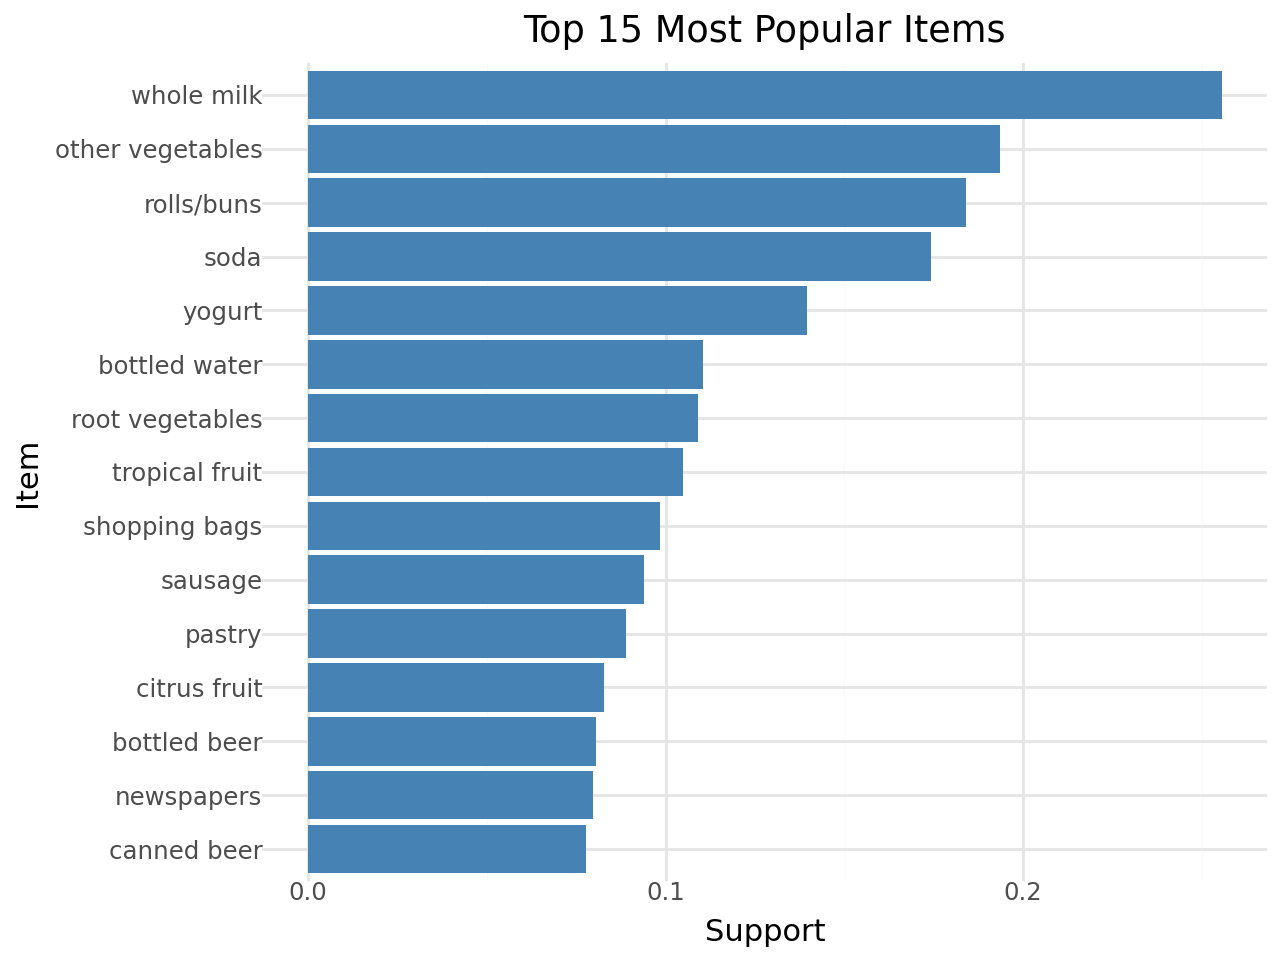

In [34]:
item_support = basket.mean().sort_values(ascending=False)

top_15 = item_support.head(15).reset_index()
top_15.columns = ["item", "support"]
top_15["item"] = pd.Categorical(top_15["item"], categories=top_15["item"].iloc[::-1], ordered=True)

plot = (
    ggplot(top_15, aes(x="item", y="support"))
    + geom_col(fill="steelblue")
    + coord_flip()
    + labs(x="Item", y="Support", title="Top 15 Most Popular Items")
    + theme_minimal()
)
plot

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?

- **Most popular item**: `whole milk` is the most popular item, appearing in approximately **25.55%** of all baskets (support of ~0.256).
- **Other common items**: `other vegetables` (~19.3%), `rolls/buns` (~18.4%), `soda` (~17.4%), and `yogurt` (~14.0%) are also highly common.
- **What this suggests about co-occurrence by chance**: Since `whole milk` is present in more than 1 in 4 baskets, and `other vegetables` is present in nearly 1 in 5, any random combination of items is highly likely to contain at least one of these popular items purely by chance. For example, if we pick random baskets, many of them will contain both `whole milk` and `other vegetables` simply because of their high individual frequencies, not because of a true underlying behavioral association. This highlights why high support or high confidence alone is not enough to identify meaningful rules, and why we need metrics like **lift** to measure how much more often items co-occur compared to what we would expect by chance.

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [35]:
both = (basket["yogurt"] & basket["whole milk"]).sum()
yogurt_total = basket["yogurt"].sum()
confidence = both / yogurt_total

print(f"Support of both: {both / len(basket):.6f} ({both} baskets)")
print(f"Support of yogurt: {yogurt_total / len(basket):.6f} ({yogurt_total} baskets)")
print(f"Confidence of {{yogurt}} -> {{whole milk}}: {confidence:.6f} ({confidence:.2%})")

Support of both: 0.056024 (551 baskets)
Support of yogurt: 0.139502 (1372 baskets)
Confidence of {yogurt} -> {whole milk}: 0.401603 (40.16%)


This confidence means that about 40.16% of customers who bought yogurt also bought whole milk.

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [36]:
whole_milk_support = basket["whole milk"].mean()
lift = confidence / whole_milk_support

print(f"Support of whole milk: {whole_milk_support:.6f} ({whole_milk_support:.2%})")
print(f"Lift of {{yogurt}} -> {{whole milk}}: {lift:.6f}")

Support of whole milk: 0.255516 (25.55%)
Lift of {yogurt} -> {whole milk}: 1.571735


Since the lift is 1.57 (greater than 1), it indicates a positive association.Customers who buy yogurt are about 1.57 times more likely to buy whole milk than a randomly selected customer

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [37]:
both = (basket["yogurt"] & basket["whole milk"]).sum()
whole_milk_total = basket["whole milk"].sum()
confidence_reverse = both / whole_milk_total
yogurt_support = basket["yogurt"].mean()
lift_reverse = confidence_reverse / yogurt_support

print(f"Support of both: {both / len(basket):.6f} ({both} baskets)")
print(f"Support of whole milk: {whole_milk_total / len(basket):.6f} ({whole_milk_total} baskets)")
print(f"Confidence of {{whole milk}} -> {{yogurt}}: {confidence_reverse:.6f} ({confidence_reverse:.2%})")
print(f"Lift of {{whole milk}} -> {{yogurt}}: {lift_reverse:.6f}")

Support of both: 0.056024 (551 baskets)
Support of whole milk: 0.255516 (2513 baskets)
Confidence of {whole milk} -> {yogurt}: 0.219260 (21.93%)
Lift of {whole milk} -> {yogurt}: 1.571735


About 21.93% of customers who bought whole milk also purchased yogurt. Customers who buy whole milk are approximately 1.57 times more likely to purchase yogurt compared to the base rate of yogurt being bought by any random customer.

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [38]:
def support(items, onehot):
    return onehot[items].all(axis=1).mean()

def rule_metrics(antecedent, consequent, onehot):
    combined = list(set(antecedent + consequent))
    support_both = support(combined, onehot)
    support_ant = support(antecedent, onehot)
    support_cons = support(consequent, onehot)
    confidence = support_both / support_ant if support_ant > 0 else 0.0
    lift = confidence / support_cons if support_cons > 0 else 0.0
    return pd.Series({
        "support": support_both,
        "confidence": confidence,
        "lift": lift
    })

test_metrics = rule_metrics(["yogurt"], ["whole milk"], basket)
test_metrics

,0
support,0.056024
confidence,0.401603
lift,1.571735


10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

In [39]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [40]:
metrics_df = antecedents.apply(lambda x: rule_metrics([x], ["whole milk"], basket))
metrics_df.index = antecedents
metrics_df = metrics_df.sort_values(by="lift", ascending=False)

metrics_df

,support,confidence,lift
yogurt,0.056024,0.401603,1.571735
other vegetables,0.074835,0.386758,1.513634
bottled water,0.034367,0.310948,1.216940
rolls/buns,0.056634,0.307905,1.205032
soda,0.040061,0.229738,0.899112


12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [41]:
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)
frequent_itemsets["n_items"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets

,support,itemsets,n_items
0,0.033452,(UHT-milk),1
1,0.017692,(baking powder),1
2,0.052466,(beef),1
3,0.033249,(berries),1
4,0.026029,(beverages),1
...,...,...,...
328,0.011998,"(tropical fruit, whole milk, root vegetables)",3
329,0.014540,"(yogurt, whole milk, root vegetables)",3
330,0.010473,"(yogurt, whole milk, soda)",3
331,0.015150,"(yogurt, tropical fruit, whole milk)",3


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [42]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.20)
print(f"Number of rules generated: {len(rules)}")

Number of rules generated: 234


14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [43]:
rules_display = rules.copy()
rules_display["antecedent"] = rules_display["antecedents"].apply(lambda x: ", ".join(list(x)))
rules_display["consequent"] = rules_display["consequents"].apply(lambda x: ", ".join(list(x)))
rules_display["transactions"] = (rules_display["support"] * len(basket)).round().astype(int)
columns_to_show = ["antecedent", "consequent", "support", "confidence", "lift", "transactions"]
rules_display[columns_to_show].head(8)

,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [44]:
top_10_confidence = rules_display[columns_to_show].sort_values(by="confidence", ascending=False).head(10)
top_10_confidence

,antecedent,consequent,support,confidence,lift,transactions
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
185,"tropical fruit, root vegetables",other vegetables,0.012303,0.584541,3.020999,121
163,"yogurt, curd",whole milk,0.010066,0.582353,2.279125,99
154,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885,113
222,"tropical fruit, root vegetables",whole milk,0.011998,0.570048,2.230969,118
225,"yogurt, root vegetables",whole milk,0.014540,0.562992,2.203354,143
166,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336,121
232,"yogurt, whipped/sour cream",whole milk,0.010880,0.524510,2.052747,107
214,"rolls/buns, root vegetables",whole milk,0.012710,0.523013,2.046888,125
172,"other vegetables, pip fruit",whole milk,0.013523,0.517510,2.025351,133


16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [45]:
top_10_lift = rules_display[columns_to_show].sort_values(by="lift", ascending=False).head(10)
top_10_lift

,antecedent,consequent,support,confidence,lift,transactions
156,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
207,"yogurt, other vegetables",whipped/sour cream,0.010168,0.234192,3.267062,100
184,"tropical fruit, other vegetables",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
185,"tropical fruit, root vegetables",other vegetables,0.012303,0.584541,3.020999,121
190,root vegetables,"whole milk, other vegetables",0.023183,0.212687,2.842082,228
187,"whole milk, other vegetables",root vegetables,0.023183,0.309783,2.842082,228
155,butter,"whole milk, other vegetables",0.011490,0.207339,2.770630,113
164,"whole milk, curd",yogurt,0.010066,0.385214,2.761356,99


17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [46]:
interesting_rules = rules[
    (rules["confidence"] >= 0.30) & (rules["lift"] >= 1.5)
].sort_values(by="lift", ascending=False)

interesting_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
156,"(citrus fruit, other vegetables)",(root vegetables),0.028876,0.108998,0.010371,0.359155,3.295045,1.0,0.007224,1.390354,0.717225,0.081340,0.280759,0.227152
184,"(tropical fruit, other vegetables)",(root vegetables),0.035892,0.108998,0.012303,0.342776,3.144780,1.0,0.008391,1.355705,0.707403,0.092791,0.262376,0.227825
2,(beef),(root vegetables),0.052466,0.108998,0.017387,0.331395,3.040367,1.0,0.011668,1.332628,0.708251,0.120677,0.249603,0.245455
157,"(citrus fruit, root vegetables)",(other vegetables),0.017692,0.193493,0.010371,0.586207,3.029608,1.0,0.006948,1.949059,0.681990,0.051646,0.486932,0.319903
185,"(tropical fruit, root vegetables)",(other vegetables),0.021047,0.193493,0.012303,0.584541,3.020999,1.0,0.008231,1.941244,0.683367,0.060835,0.484867,0.324062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,(onions),(whole milk),0.031012,0.255516,0.012100,0.390164,1.526965,1.0,0.004176,1.220794,0.356151,0.044090,0.180861,0.218759
72,(hygiene articles),(whole milk),0.032944,0.255516,0.012811,0.388889,1.521975,1.0,0.004394,1.218247,0.354642,0.046477,0.179148,0.219514
17,(brown bread),(whole milk),0.064870,0.255516,0.025216,0.388715,1.521293,1.0,0.008641,1.217899,0.366435,0.085429,0.178914,0.243701
106,(other vegetables),(whole milk),0.193493,0.255516,0.074835,0.386758,1.513634,1.0,0.025394,1.214013,0.420750,0.200000,0.176286,0.339817


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

About 1.74% of all transactions contain both beef and root vegetables. Of all customers who purchased beef, approximately 33.14% also purchased root vegetables. Customers who buy beef are about 3.04 times more likely to buy root vegetables than a randomly selected customer.

19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

In [47]:
yogurt_recommendations = rules_display[
    (rules_display["antecedent"].str.contains("yogurt") | rules_display["consequent"].str.contains("yogurt"))
].sort_values(by="lift", ascending=False)

yogurt_recommendations[columns_to_show].head(10)

,antecedent,consequent,support,confidence,lift,transactions
207,"yogurt, other vegetables",whipped/sour cream,0.010168,0.234192,3.267062,100
164,"whole milk, curd",yogurt,0.010066,0.385214,2.761356,99
191,"yogurt, other vegetables",root vegetables,0.012913,0.297424,2.728698,127
203,"yogurt, other vegetables",tropical fruit,0.012303,0.283372,2.700550,121
192,"yogurt, root vegetables",other vegetables,0.012913,0.500000,2.584078,127
230,"yogurt, whole milk",tropical fruit,0.015150,0.270417,2.577089,149
231,"tropical fruit, whole milk",yogurt,0.015150,0.358173,2.567516,149
208,"yogurt, whipped/sour cream",other vegetables,0.010168,0.490196,2.533410,100
209,"other vegetables, whipped/sour cream",yogurt,0.010168,0.352113,2.524073,100
202,"tropical fruit, other vegetables",yogurt,0.012303,0.342776,2.457146,121


Other vegetables, whole milk, curd, root vegetables, and whipped/sour cream are all good products to link with Yogurt

---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).